# Evaluación Parcial — Actividad 1: Pipeline de Machine Learning Clásico

## A. Presentación

**Curso:** Ingeniería del Conocimiento (ISO56B)
**Semestre:** 2026-II
**Fecha:** 18/10/2026

**Integrante:**
- Gutierrez Vega Bill Toño — código 2012100229F
- Quispealaya Vera Elias Carlos — código 2024200203H
- López Granados Karito Dali Yoselyn — código 2024200191I
- Paredes Huarcaya Michael — código 202420025F


### Dataset elegido
**Nombre:** Richter's Predictor: Modeling Earthquake Damage (daño en edificios por el terremoto de Nepal, 2015)

**Fuentes:**
- Descarga del dataset (Kaggle): https://www.kaggle.com/datasets/mullerismail/richters-predictor-modeling-earthquake-damage
- Competencia de origen (DrivenData): https://www.drivendata.org/competitions/57/nepal-earthquake/
- Portal original de datos abiertos del terremoto de Nepal: http://eq2015.klldev.org

**Justificación de la elección:**
- Son datos reales: provienen de la encuesta casa por casa que realizó el Gobierno de Nepal tras el terremoto de Gorkha (7.8 Mw, 25 de abril de 2015).
- Es relevante para el Perú, que es un país de alta actividad sísmica.
- Cumple los requisitos de la guía: 260,601 registros, 38 variables predictoras (numéricas, categóricas y binarias) y 3 clases.
- No fue utilizado en las sesiones ni en los laboratorios del curso.

### Descripción del problema
El problema consiste en predecir el nivel de daño que sufrió un edificio tras un terremoto (`damage_grade`: 1 = daño bajo, 2 = daño medio, 3 = destrucción casi total) a partir de sus características: ubicación geográfica, antigüedad, número de pisos, tipo de cimiento, techo y materiales de construcción, uso y situación legal. Es un problema de clasificación multiclase con aprendizaje supervisado. Un modelo así podría ayudar a priorizar inspecciones y ayudas tras un sismo.

---

# B. Carga y Análisis Exploratorio de Datos (EDA)

En esta sección se carga el dataset y se explora para conocer su estructura, la calidad de los datos y la distribución de la variable objetivo (`damage_grade`). Lo que se encuentre aquí guía las decisiones de preprocesamiento de la Sección C.

### B.1 Carga del dataset:
 se carga `train_merged.csv`, que resulta de unir el archivo de valores y el de etiquetas por `building_id`.

In [10]:
import pandas as pd

# Carga del dataset unido (valores + etiquetas), ubicado junto al notebook
df = pd.read_csv("train_merged.csv")
print("Dataset cargado:", df.shape)

Dataset cargado: (260601, 40)


### B.2 Vista general del dataset

Se revisan las primeras filas, las dimensiones, los tipos de datos y la presencia de valores nulos o repetidos, para verificar que la carga fue correcta y conocer la calidad de los datos.

In [11]:
pd.set_option("display.max_columns", None)  # evita que pandas oculte columnas
df.head()

,building_id,geo_level_1_id,geo_level_2_id,geo_level_3_id,count_floors_pre_eq,age,area_percentage,height_percentage,land_surface_condition,foundation_type,roof_type,ground_floor_type,other_floor_type,position,plan_configuration,has_superstructure_adobe_mud,has_superstructure_mud_mortar_stone,has_superstructure_stone_flag,has_superstructure_cement_mortar_stone,has_superstructure_mud_mortar_brick,has_superstructure_cement_mortar_brick,has_superstructure_timber,has_superstructure_bamboo,has_superstructure_rc_non_engineered,has_superstructure_rc_engineered,has_superstructure_other,legal_ownership_status,count_families,has_secondary_use,has_secondary_use_agriculture,has_secondary_use_hotel,has_secondary_use_rental,has_secondary_use_institution,has_secondary_use_school,has_secondary_use_industry,has_secondary_use_health_post,has_secondary_use_gov_office,has_secondary_use_use_police,has_secondary_use_other,damage_grade
0,802906,6,487,12198,2,30,6,5,t,r,n,f,q,t,d,1,1,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,3
1,28830,8,900,2812,2,10,8,7,o,r,n,x,q,s,d,0,1,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,2
2,94947,21,363,8973,2,10,5,5,t,r,n,f,x,t,d,0,1,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,3
3,590882,22,418,10694,2,10,6,5,t,r,n,f,x,s,d,0,1,0,0,0,0,1,1,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,2
4,201944,11,131,1488,3,30,8,9,t,r,n,f,x,s,d,1,0,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,3


In [12]:
print("Filas y columnas:", df.shape)

Filas y columnas: (260601, 40)


In [13]:
df.info()
print()
print(df.dtypes.value_counts())  # resumen: cuántas columnas hay de cada tipo

<class 'pandas.DataFrame'>
RangeIndex: 260601 entries, 0 to 260600
Data columns (total 40 columns):
 #   Column                                  Non-Null Count   Dtype
---  ------                                  --------------   -----
 0   building_id                             260601 non-null  int64
 1   geo_level_1_id                          260601 non-null  int64
 2   geo_level_2_id                          260601 non-null  int64
 3   geo_level_3_id                          260601 non-null  int64
 4   count_floors_pre_eq                     260601 non-null  int64
 5   age                                     260601 non-null  int64
 6   area_percentage                         260601 non-null  int64
 7   height_percentage                       260601 non-null  int64
 8   land_surface_condition                  260601 non-null  str  
 9   foundation_type                         260601 non-null  str  
 10  roof_type                               260601 non-null  str  
 11  ground_floo

In [14]:
nulos = df.isna().sum()
print("Total de valores nulos:", nulos.sum())
print(nulos[nulos > 0])  # solo las columnas que tengan nulos

Total de valores nulos: 0
Series([], dtype: int64)


In [15]:
# Se excluye building_id: es único, así que con él nunca habría duplicados
print("Filas repetidas (sin contar el id):", df.drop(columns="building_id").duplicated().sum())

Filas repetidas (sin contar el id): 12319


### B.3 Distribución de la variable objetivo

Se analiza la frecuencia de cada nivel de daño (`damage_grade`) para saber si las clases están balanceadas, lo que influye en la elección de métricas y en el tipo de split.

              conteo  porcentaje (%)
damage_grade                        
1              25124            9.64
2             148259           56.89
3              87218           33.47


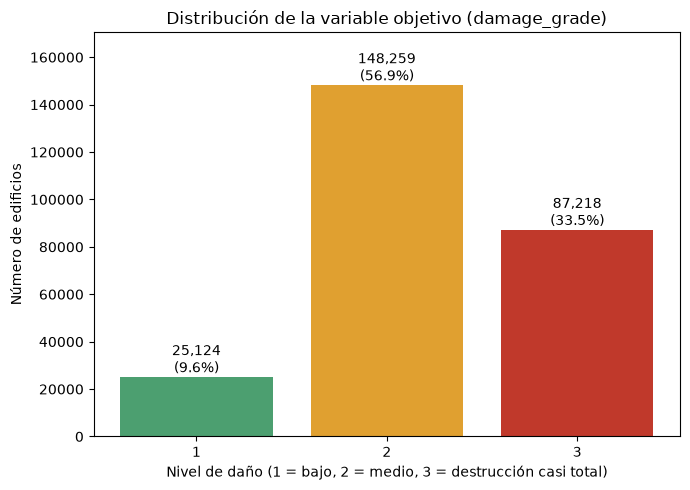

In [16]:
import matplotlib.pyplot as plt

conteo = df["damage_grade"].value_counts().sort_index()
porcentaje = df["damage_grade"].value_counts(normalize=True).sort_index() * 100

# Tabla resumen
print(pd.DataFrame({"conteo": conteo, "porcentaje (%)": porcentaje.round(2)}))

# Gráfico de barras con conteo y porcentaje sobre cada barra
fig, ax = plt.subplots(figsize=(7, 5))
barras = ax.bar(conteo.index.astype(str), conteo.values, color=["#4C9F70", "#E0A030", "#C0392B"])
for barra, n, p in zip(barras, conteo.values, porcentaje.values):
    ax.text(barra.get_x() + barra.get_width() / 2, barra.get_height(),
            f"{n:,}\n({p:.1f}%)", ha="center", va="bottom")

ax.set_title("Distribución de la variable objetivo (damage_grade)")
ax.set_xlabel("Nivel de daño (1 = bajo, 2 = medio, 3 = destrucción casi total)")
ax.set_ylabel("Número de edificios")
ax.set_ylim(0, conteo.max() * 1.15)  # deja espacio para las etiquetas
plt.tight_layout()
plt.show()

### B.4 Estadísticas descriptivas de las variables numéricas

Se resumen las variables numéricas con medidas de tendencia central y dispersión, para detectar escalas distintas y posibles valores extremos. Se excluyen los identificadores geográficos (`geo_level_*_id`), que son códigos de zona y no cantidades, y las variables binarias 0/1.

In [17]:
numericas = ["count_floors_pre_eq", "age", "area_percentage", "height_percentage", "count_families"]
df[numericas].describe(percentiles=[0.25, 0.5, 0.75, 0.99]).round(2)

,count_floors_pre_eq,age,area_percentage,height_percentage,count_families
count,260601.00,260601.00,260601.00,260601.00,260601.00
mean,2.13,26.54,8.02,5.43,0.98
std,0.73,73.57,4.39,1.92,0.42
min,1.00,0.00,1.00,2.00,0.00
25%,2.00,10.00,5.00,4.00,1.00
50%,2.00,15.00,7.00,5.00,1.00
75%,2.00,30.00,9.00,6.00,1.00
99%,4.00,100.00,23.00,11.00,2.00
max,9.00,995.00,100.00,32.00,9.00


### B.5 Visualizaciones adicionales

Se presentan gráficos que muestran la distribución de variables clave y su relación con el nivel de daño.

#### B.5.1 Distribución de la edad del edificio

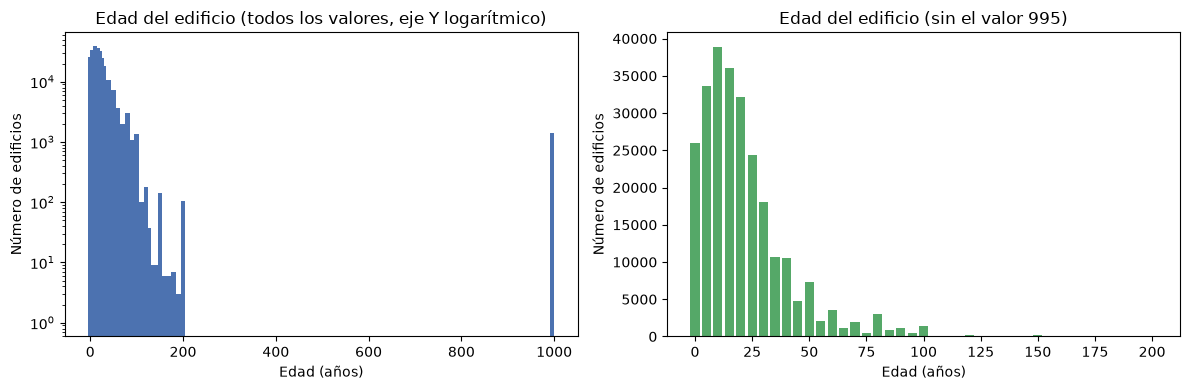

In [18]:
conteo_edad = df["age"].value_counts().sort_index()
sin_995 = conteo_edad[conteo_edad.index <= 200]  # todos los valores mayores a 200 son 995

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Todos los valores, eje Y logarítmico para que se vea el valor aislado
axes[0].bar(conteo_edad.index, conteo_edad.values, width=10, color="#4C72B0")
axes[0].set_yscale("log")
axes[0].set_title("Edad del edificio (todos los valores, eje Y logarítmico)")
axes[0].set_xlabel("Edad (años)")
axes[0].set_ylabel("Número de edificios")

# Sin el valor 995
axes[1].bar(sin_995.index, sin_995.values, width=4, color="#55A868")
axes[1].set_title("Edad del edificio (sin el valor 995)")
axes[1].set_xlabel("Edad (años)")
axes[1].set_ylabel("Número de edificios")

plt.tight_layout()
plt.show()

#### B.5.2 Nivel de daño según el tipo de cimiento

Se compara la distribución del daño dentro de cada tipo de cimiento (`foundation_type`), para ver si el tipo de construcción se relaciona con el nivel de daño. Los códigos son letras y no se conoce su significado.

damage_grade         1       2      3
foundation_type                      
h                  358     579    511
i                 6004    4354    221
r                10720  125515  82961
u                 3689    8541   2030
w                 4353    9270   1495


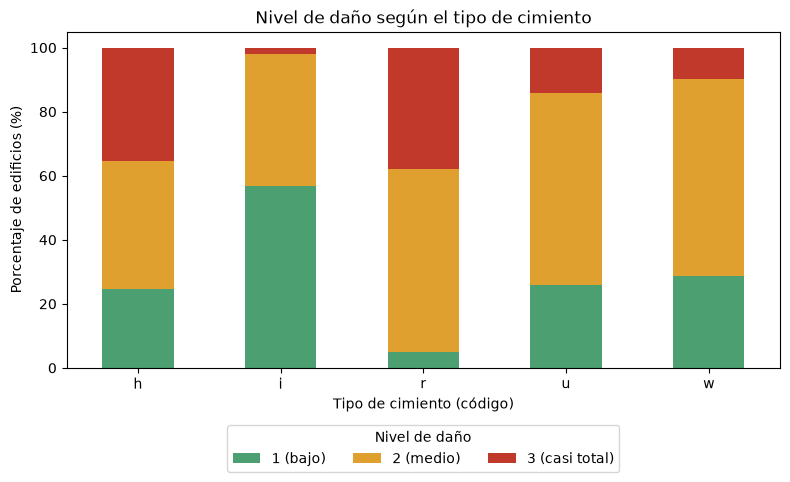

In [19]:
# Tamaño de cada categoría (para no interpretar categorías con pocos edificios)
conteos = pd.crosstab(df["foundation_type"], df["damage_grade"])
print(conteos)

# Porcentaje de cada nivel de daño dentro de cada tipo de cimiento
porcentajes = pd.crosstab(df["foundation_type"], df["damage_grade"], normalize="index") * 100
porcentajes = porcentajes.rename(columns={1: "1 (bajo)", 2: "2 (medio)", 3: "3 (casi total)"})

ax = porcentajes.plot(kind="bar", stacked=True, figsize=(8, 5),
                      color=["#4C9F70", "#E0A030", "#C0392B"])
ax.set_title("Nivel de daño según el tipo de cimiento")
ax.set_xlabel("Tipo de cimiento (código)")
ax.set_ylabel("Porcentaje de edificios (%)")
ax.legend(title="Nivel de daño", loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

#### B.5.3 Nivel de daño según el número de pisos

Se compara la distribución del daño según el número de pisos del edificio antes del terremoto (`count_floors_pre_eq`), para ver si la altura se relaciona con el nivel de daño.

damage_grade             1      2      3
count_floors_pre_eq                     
1                     8969  20798  10674
2                    12593  93968  50062
3                     2537  28479  24601
4                      707   3374   1343
5                      254   1481    511
6                       53    133     23
7                       10     25      4
8                        0      1      0
9                        1      0      0


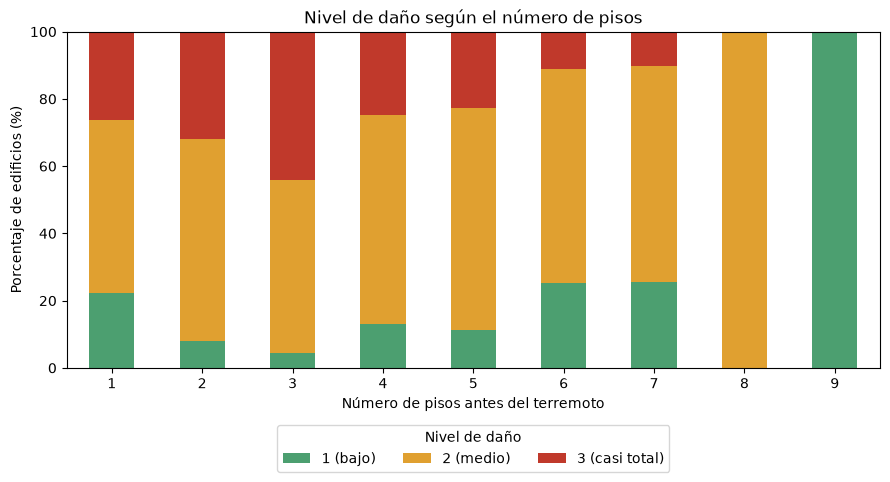

In [20]:
# Tamaño de cada categoría (los pisos altos tienen pocos edificios)
conteos_pisos = pd.crosstab(df["count_floors_pre_eq"], df["damage_grade"])
print(conteos_pisos)

# Porcentaje de cada nivel de daño dentro de cada número de pisos
porcentajes_pisos = pd.crosstab(df["count_floors_pre_eq"], df["damage_grade"], normalize="index") * 100
porcentajes_pisos = porcentajes_pisos.rename(columns={1: "1 (bajo)", 2: "2 (medio)", 3: "3 (casi total)"})

ax = porcentajes_pisos.plot(kind="bar", stacked=True, figsize=(9, 5),
                            color=["#4C9F70", "#E0A030", "#C0392B"])
ax.set_title("Nivel de daño según el número de pisos")
ax.set_xlabel("Número de pisos antes del terremoto")
ax.set_ylabel("Porcentaje de edificios (%)")
ax.legend(title="Nivel de daño", loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

#### B.5.3.a Nivel de daño según el número de pisos

Se compara la distribución del daño según el número de pisos del edificio antes del terremoto (`count_floors_pre_eq`), para ver si la altura se relaciona con el nivel de daño y se concidera agrupar los edificios con pisos mayores a 6 para mayor comprensión.

damage_grade             1      2      3
count_floors_pre_eq                     
1                     8969  20798  10674
2                    12593  93968  50062
3                     2537  28479  24601
4                      707   3374   1343
5                      254   1481    511
6 o más                 64    159     27


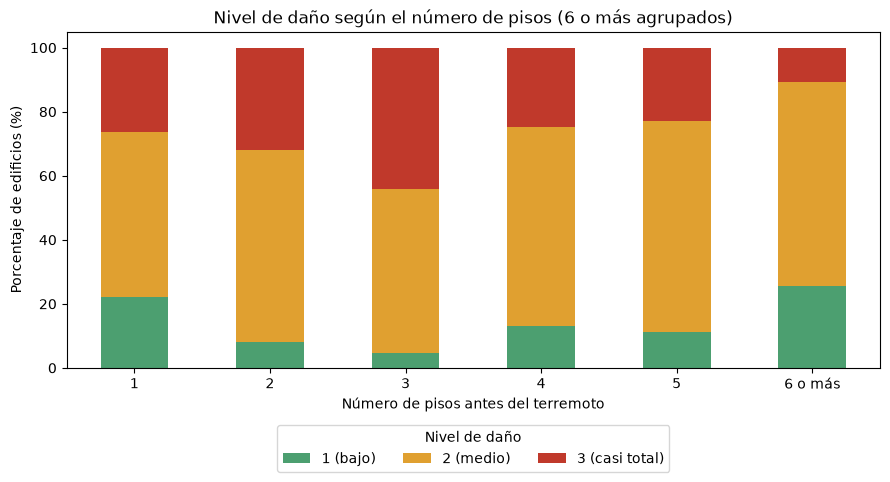

In [21]:
# Solo para el gráfico: se agrupan los edificios de 6 o más pisos (son muy pocos)
pisos = df["count_floors_pre_eq"].clip(upper=6).map(lambda p: "6 o más" if p == 6 else str(p))

conteos_pisos = pd.crosstab(pisos, df["damage_grade"])
print(conteos_pisos)

porcentajes_pisos = pd.crosstab(pisos, df["damage_grade"], normalize="index") * 100
porcentajes_pisos = porcentajes_pisos.rename(columns={1: "1 (bajo)", 2: "2 (medio)", 3: "3 (casi total)"})

ax = porcentajes_pisos.plot(kind="bar", stacked=True, figsize=(9, 5),
                            color=["#4C9F70", "#E0A030", "#C0392B"])
ax.set_title("Nivel de daño según el número de pisos (6 o más agrupados)")
ax.set_xlabel("Número de pisos antes del terremoto")
ax.set_ylabel("Porcentaje de edificios (%)")
ax.legend(title="Nivel de daño", loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

#### B.5.4 Mapa de correlación de las variables numéricas

Se calcula la correlación de Pearson entre las variables numéricas y el nivel de daño. Se excluyen los identificadores geográficos (son códigos, no cantidades) y, solo para este cálculo, se omite el valor 995 de `age`, que parece un código de dato faltante.

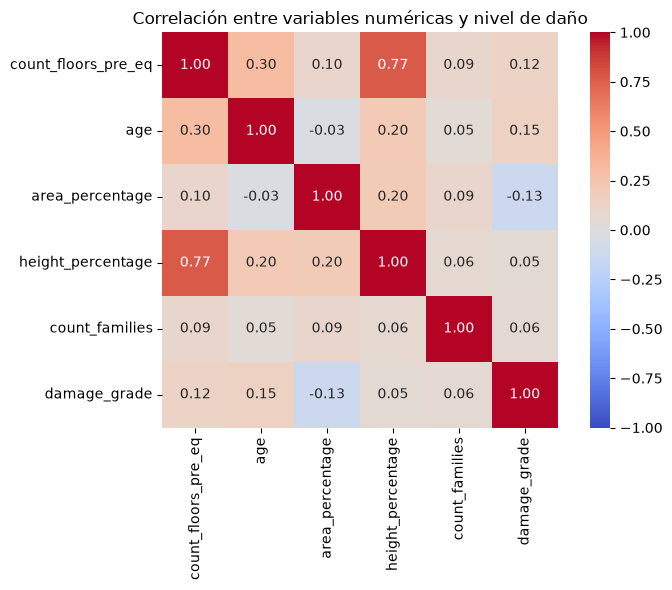

In [22]:
import numpy as np
import seaborn as sns

columnas = ["count_floors_pre_eq", "age", "area_percentage", "height_percentage",
            "count_families", "damage_grade"]

# Copia para el análisis: df no se modifica
datos_corr = df[columnas].copy()
datos_corr["age"] = datos_corr["age"].replace(995, np.nan)

corr = datos_corr.corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Correlación entre variables numéricas y nivel de daño")
plt.tight_layout()
plt.show()

### B.6 Conclusiones del EDA

- El dataset tiene 260,601 edificios y 38 variables predictoras, sin valores nulos formales. 

- La variable objetivo está desbalanceada (9.64 % daño 1, 56.89 % daño 2 y 33.47 % daño 3): predecir siempre la clase 2 ya daría un accuracy cercano al 57 %, por lo que se usarán F1 macro, recall por clase y un split estratificado. 

- La variable `age` avanza en pasos de 5 años y presenta el valor 995 en 1,390 edificios, aislado del resto y probablemente un código de dato faltante, que se tratará en C.1; el 0 se conserva por ser un valor legítimo.  

- Las categóricas están anonimizadas con letras sin orden, así que se codificarán sin imponer un orden (One-Hot), y los identificadores geográficos son códigos de zona, no cantidades, por lo que su codificación se decidirá en C.2. 

- El daño se asocia con el tipo de cimiento y con el número de pisos (esta última de forma no lineal), mientras que la correlación lineal más alta con el daño es débil (`age`, 0.15), lo que sugiere probar modelos capaces de capturar relaciones no lineales. Se conservan las 12,319 filas con características idénticas, porque corresponden a edificios distintos.

---

# C. Preprocesamiento

En esta sección se preparan los datos para el modelado. Los pasos que usan estadísticas del dataset (imputación, codificación, escalado) se ajustan únicamente con el conjunto de entrenamiento, para evitar que el conjunto de prueba influya en el preprocesamiento (data leakage).

### C.1 Tratamiento de valores nulos

El dataset no tiene valores nulos formales (0 en todas las columnas). Sin embargo, `age` contiene el valor 995 en 1,390 edificios (0.53 %), aislado del resto: no existen valores entre 201 y 994, y la edad avanza en pasos de 5 años. Se interpreta como un código de dato faltante.

**Estrategia:**
- Se reemplaza 995 por `NaN` y se crea la columna indicadora `age_desconocida` (1 si la edad era 995), para conservar la información de que el dato faltaba.
- Se imputará con la **mediana** de `age` calculada solo con train, después del split (C.4). Se elige la mediana y no la media porque la distribución es asimétrica y la media está inflada por los propios valores 995.
- No se eliminan las filas, para no perder información de 1,390 edificios.
- El valor 0 se conserva: en una variable en pasos de 5 años, corresponde a edificios muy recientes.
- `count_families == 0` (20,862 edificios, 8.0 %) se conserva: puede corresponder a edificios sin familias registradas, y no hay evidencia de que sea un error.

In [23]:
import numpy as np

# df_prep es una copia: df queda intacto como referencia de los datos originales
df_prep = df.copy()

# Indicador de que la edad era desconocida (995) y recodificación como valor faltante
df_prep["age_desconocida"] = (df_prep["age"] == 995).astype(int)
df_prep["age"] = df_prep["age"].replace(995, np.nan)

print("Valores nulos en age:", df_prep["age"].isna().sum())
print("Edificios con age_desconocida = 1:", df_prep["age_desconocida"].sum())
print("Edad máxima (sin los NaN):", df_prep["age"].max())

Valores nulos en age: 1390
Edificios con age_desconocida = 1: 1390
Edad máxima (sin los NaN): 200.0


### C.2 Codificación de variables categóricas

Los modelos requieren entradas numéricas, por lo que las variables categóricas se codifican. Se distinguen dos grupos: las variables con pocas categorías (letras anonimizadas) y las columnas geográficas, con muchas zonas.

#### Variables con letras (8 columnas)

`land_surface_condition`, `foundation_type`, `roof_type`, `ground_floor_type`, `other_floor_type`, `position`, `plan_configuration` y `legal_ownership_status`. Sus valores son letras anonimizadas, sin orden ni significado conocido.

**Herramientas de codificación:**
- **`LabelEncoder`** (scikit-learn): reemplaza cada categoría por un número entero (0, 1, 2...). Es simple, pero introduce un orden que no existe entre las categorías.
- **`OneHotEncoder`** (scikit-learn): crea una columna 0/1 por cada categoría; cada fila tiene un 1 solo en la columna de su categoría. No impone orden y recuerda las categorías vistas al ajustarlo, por lo que se usa dentro de pipelines.
- **`pd.get_dummies`** (pandas): hace lo mismo que `OneHotEncoder`, pero directamente sobre un DataFrame y con nombres de columna legibles (por ejemplo `foundation_type_r`). No recuerda las categorías, así que sirve cuando se codifica todo el DataFrame de una vez.

**Estrategia:** se usa `pd.get_dummies` (One-Hot) y no `LabelEncoder`, porque las letras no tienen orden y un número entero haría que los modelos interpreten distancias inexistentes. Cada columna tiene pocas categorías, por lo que el número de columnas nuevas es manejable. Esta codificación solo depende del conjunto de categorías y no de estadísticas de los datos, por lo que puede aplicarse antes del split sin data leakage.

**Funciones usadas en el código:**
- **`nunique()`:** cuenta cuántos valores distintos tiene cada columna.
- **`value_counts()`:** cuenta cuántas veces aparece cada valor de una columna.
- **`dtype=int`:** hace que las columnas nuevas sean 0/1 y no `True`/`False`.

In [24]:
# revisar las categorías

# Variables categóricas con letras (nominales, sin orden)
cols_cat = ["land_surface_condition", "foundation_type", "roof_type", "ground_floor_type",
            "other_floor_type", "position", "plan_configuration", "legal_ownership_status"]

# Número de categorías de cada variable
print(df_prep[cols_cat].nunique())
print("Columnas que se generarán con One-Hot:", df_prep[cols_cat].nunique().sum())
print()

# Tamaño de cada categoría (para detectar categorías con muy pocos edificios)
for c in cols_cat:
    print(c, df_prep[c].value_counts().to_dict())

land_surface_condition     3
foundation_type            5
roof_type                  3
ground_floor_type          5
other_floor_type           4
position                   4
plan_configuration        10
legal_ownership_status     4
dtype: int64
Columnas que se generarán con One-Hot: 38

land_surface_condition {'t': 216757, 'n': 35528, 'o': 8316}
foundation_type {'r': 219196, 'w': 15118, 'u': 14260, 'i': 10579, 'h': 1448}
roof_type {'n': 182842, 'q': 61576, 'x': 16183}
ground_floor_type {'f': 209619, 'x': 24877, 'v': 24593, 'z': 1004, 'm': 508}
other_floor_type {'q': 165282, 'x': 43448, 'j': 39843, 's': 12028}
position {'s': 202090, 't': 42896, 'j': 13282, 'o': 2333}
plan_configuration {'d': 250072, 'q': 5692, 'u': 3649, 's': 346, 'c': 325, 'a': 252, 'o': 159, 'm': 46, 'n': 38, 'f': 22}
legal_ownership_status {'v': 250939, 'a': 5512, 'w': 2677, 'r': 1473}


In [25]:
# One-Hot de las 8 variables; dtype=int deja columnas 0/1

df_enc = pd.get_dummies(df_prep, columns=cols_cat, dtype=int)
print("Antes:", df_prep.shape, "| Después:", df_enc.shape)

Antes: (260601, 41) | Después: (260601, 71)


#### Columnas geográficas

`geo_level_1_id`, `geo_level_2_id` y `geo_level_3_id` son códigos de zona (de la región más grande a la más específica), no cantidades, por lo que no pueden usarse como números. Se mide cuántas zonas hay en cada nivel, cuántos edificios tiene cada zona y si el daño varía entre regiones.

**Funciones usadas en el código:**
- **`groupby()`:** agrupa las filas por el valor de una columna (aquí, por región) para calcular algo dentro de cada grupo.
- **`lambda`:** una función corta y sin nombre, escrita en una línea. Aquí calcula, dentro de cada región, la proporción de edificios con daño 3.
- **`sort_values()`:** ordena los resultados de menor a mayor.
- **`axhline()`:** dibuja una línea horizontal de referencia en el gráfico.

geo_level_1_id       31
geo_level_2_id     1414
geo_level_3_id    11595
dtype: int64

Edificios por zona de nivel 3 -> mediana: 14.0 | zonas con menos de 10 edificios: 4525


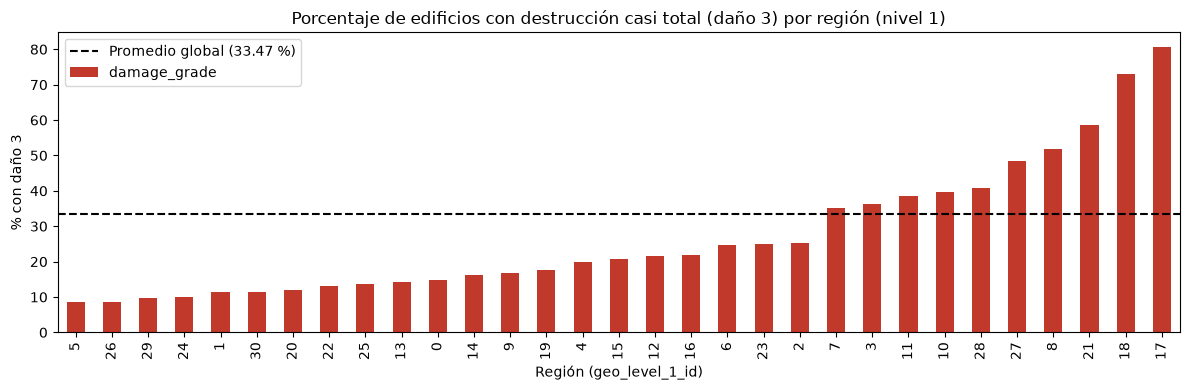

In [26]:
geo = ["geo_level_1_id", "geo_level_2_id", "geo_level_3_id"]

# Cuántas zonas distintas hay en cada nivel
print(df[geo].nunique())

# Cuántos edificios tiene cada zona de nivel 3
tam3 = df["geo_level_3_id"].value_counts()
print("\nEdificios por zona de nivel 3 -> mediana:", tam3.median(),
      "| zonas con menos de 10 edificios:", (tam3 < 10).sum())

# Porcentaje de edificios con daño 3 en cada región de nivel 1
pct3 = df.groupby("geo_level_1_id")["damage_grade"].apply(lambda s: (s == 3).mean() * 100).sort_values()

ax = pct3.plot(kind="bar", figsize=(12, 4), color="#C0392B")
ax.axhline(33.47, color="black", linestyle="--", label="Promedio global (33.47 %)")
ax.set_title("Porcentaje de edificios con destrucción casi total (daño 3) por región (nivel 1)")
ax.set_xlabel("Región (geo_level_1_id)")
ax.set_ylabel("% con daño 3")
ax.legend()
plt.tight_layout()
plt.show()

#### Decisión para las columnas geográficas

Los tres niveles tienen 31, 1,414 y 11,595 valores distintos. En el nivel 3 la mediana es de 14 edificios por zona y el 39 % de las zonas tiene menos de 10. Por la ubicación se espera una relación importante con el daño, por lo que no se descartan.

**Decisión:**
- `geo_level_1_id` (31 regiones): One-Hot, con `pd.get_dummies`.
- `geo_level_2_id` y `geo_level_3_id`: **target encoding**. One-Hot generaría 1,414 y 11,595 columnas, casi todas ceros, y agrupar las zonas raras perdería justo el detalle fino que interesa conservar.

**Qué es el target encoding:**
- **Target encoding (`TargetEncoder`, scikit-learn):** reemplaza cada zona por un resumen de la variable objetivo en esa zona; aquí, la proporción de edificios de cada nivel de daño.
- **Suavizado:** mezcla el valor de la zona con el promedio global, dándole más peso al global cuando la zona tiene pocos edificios. Así una zona de 3 edificios no produce un valor extremo poco fiable.
- **Validación cruzada interna:** al codificar el conjunto de entrenamiento, el valor de cada edificio se calcula con las demás filas y no con la suya. Sin esto, el modelo vería la respuesta de cada edificio (data leakage). Las zonas que aparecen en test pero no en train reciben el promedio global.

**Importante:** como usa la etiqueta, este codificador se ajusta únicamente con el conjunto de entrenamiento, después del split (C.4), y luego se aplica al de prueba. Por eso, hasta entonces, `geo_level_2_id` y `geo_level_3_id` permanecen sin transformar y no se usan en ningún modelo.

La relevancia real de las variables geográficas se medirá en la Sección F, con importancia por permutación.

**Funciones usadas en el código:**
- **`prefix`:** texto que se antepone al nombre de las columnas nuevas (por ejemplo `geo1_17`), para reconocerlas.

In [27]:
df_enc = pd.get_dummies(df_enc, columns=["geo_level_1_id"], prefix="geo1", dtype=int)
print(df_enc.shape)

(260601, 101)


### C.3 Escalado de variables numéricas

**Qué se escala:** las 5 variables numéricas: `count_floors_pre_eq`, `age`, `area_percentage`, `height_percentage` y `count_families`. No se escalan las variables 0/1 (banderas y columnas One-Hot), que ya están en una escala común, ni los identificadores geográficos, que se codifican aparte.

**Por qué escalar:** las variables tienen rangos muy distintos (por ejemplo, `age` llega hasta 200 y `count_floors_pre_eq` hasta 9). Los modelos basados en distancias o en gradientes (regresión logística, SVM, KNN) se dejan dominar por las variables de mayor rango. Sin escalar, en un SVM `age` pesaría mucho más que el número de pisos solo por estar en unidades más grandes. Los árboles y el Random Forest no lo necesitan, pero escalar no los perjudica.

**Escaladores considerados:**
- **`StandardScaler`** (scikit-learn): resta la media y divide por la desviación estándar, `(x − media) / desviación`. Deja cada variable con media 0 y desviación 1, sin un rango fijo.
- **`MinMaxScaler`** (scikit-learn): lleva cada variable al rango [0, 1], con `(x − mín) / (máx − mín)`. Depende directamente del mínimo y el máximo.

**Decisión: `StandardScaler`.** Hay valores extremos: en `area_percentage` el máximo es 100 y el percentil 99 es 23, y algo parecido ocurre en `count_families` y `height_percentage`. Con `MinMaxScaler`, un solo máximo extremo comprimiría casi todos los valores en un tramo muy pequeño cerca de 0. `StandardScaler` usa la media y la desviación, que reflejan toda la distribución y no solo los dos extremos. Los valores extremos siguen presentes, pero no aplastan al resto.

**Importante:** el escalador se ajusta únicamente con el conjunto de entrenamiento (C.4) y luego se aplica a test con esos mismos valores de media y desviación, para evitar data leakage. La imputación de `age` (mediana de train) se hace antes del escalado.

**Funciones usadas en el código:**
- **`agg()`:** calcula varias medidas a la vez (aquí mínimo, máximo, media y desviación) para cada columna.
- **`quantile(0.99)`:** el valor bajo el cual está el 99 % de los datos.
- **`.T`:** transpone la tabla (filas por columnas), para leerla mejor.

In [28]:
numericas = ["count_floors_pre_eq", "age", "area_percentage", "height_percentage", "count_families"]

# Solo descriptivo: no se transforma nada (age ya tiene NaN donde era 995; se ignoran)
resumen = df_prep[numericas].agg(["min", "max", "mean", "std"]).T
resumen["p99"] = df_prep[numericas].quantile(0.99)
resumen["max / p99"] = resumen["max"] / resumen["p99"]
print(resumen.round(2))

                     min    max   mean    std   p99  max / p99
count_floors_pre_eq  1.0    9.0   2.13   0.73   4.0       2.25
age                  0.0  200.0  21.34  19.61  90.0       2.22
area_percentage      1.0  100.0   8.02   4.39  23.0       4.35
height_percentage    2.0   32.0   5.43   1.92  11.0       2.91
count_families       0.0    9.0   0.98   0.42   2.0       4.50


### C.4 División train/test y ajuste del preprocesamiento

Se separa el 80 % de los datos para entrenar y el 20 % para evaluar. Los pasos que usan estadísticas de los datos (imputación de `age`, target encoding de las columnas geográficas y escalado) se ajustan **solo con el conjunto de entrenamiento** y luego se aplican al de prueba, para que el conjunto de prueba no influya en el preprocesamiento (data leakage).

**Orden:** (1) split estratificado, (2) imputación de `age`, (3) target encoding de `geo_level_2_id` y `geo_level_3_id`, (4) escalado de las variables numéricas, (5) aplicación a test.

#### Split estratificado

Se separan las variables predictoras (`X`) de la variable objetivo (`y`, `damage_grade`). `building_id` se excluye porque es solo un identificador. Como las clases están desbalanceadas (9.64 %, 56.89 % y 33.47 %), el split es **estratificado**: mantiene esas proporciones en train y en test. Sin estratificar, el azar podría dejar menos edificios de la clase 1 en alguno de los dos conjuntos y hacer inestables las métricas.

**Funciones usadas en el código:**
- **`train_test_split` (scikit-learn):** divide los datos en dos partes, una para entrenar y otra para evaluar.
- **`test_size=0.2`:** el 20 % de los datos va a test.
- **`stratify=y`:** mantiene en ambos conjuntos la misma proporción de cada clase de `y`.
- **`random_state=42`:** fija la semilla del azar para que el split sea siempre el mismo y el trabajo sea reproducible. El número 42 es arbitrario.
- **`drop(columns=...)`:** elimina las columnas indicadas del DataFrame.

In [29]:
from sklearn.model_selection import train_test_split

# X: variables predictoras (sin el identificador ni la variable objetivo); y: variable objetivo
X = df_enc.drop(columns=["building_id", "damage_grade"])
y = df_enc["damage_grade"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)

X_train: (208480, 99) | X_test: (52121, 99)


#### Imputación de `age`

Los 1,390 edificios con `age = 995` se recodificaron como `NaN` en C.1. Ahora se reemplazan por la **mediana de `age` en el conjunto de entrenamiento**. La mediana se calcula solo con train y se aplica a train y a test, de modo que test no influye en ese valor.

**Funciones usadas en el código:**
- **`SimpleImputer` (scikit-learn):** rellena valores faltantes con un valor calculado de los datos. Con `strategy="median"` usa la mediana de la columna.
- **`fit`:** el imputador aprende de los datos (aquí, calcula la mediana). Solo se hace con train.
- **`transform`:** aplica lo aprendido a unos datos (rellena los `NaN`). Se hace con train y con test, usando siempre la mediana de train.
- **`fit_transform`:** hace `fit` y `transform` en un solo paso. Se usa solo con train.
- **`statistics_`:** guarda el valor que el imputador calculó (la mediana).

In [30]:
from sklearn.impute import SimpleImputer

print("NaN en age antes -> train:", X_train["age"].isna().sum(), "| test:", X_test["age"].isna().sum())

# fit solo con train; transform en train y en test con la mediana de train
imputador = SimpleImputer(strategy="median")
X_train["age"] = imputador.fit_transform(X_train[["age"]])
X_test["age"] = imputador.transform(X_test[["age"]])

print("Mediana de train usada para imputar:", imputador.statistics_[0])
print("NaN en age después -> train:", X_train["age"].isna().sum(), "| test:", X_test["age"].isna().sum())

NaN en age antes -> train: 1110 | test: 280
Mediana de train usada para imputar: 15.0
NaN en age después -> train: 0 | test: 0


#### Target encoding de `geo_level_2_id` y `geo_level_3_id`

Cada zona se reemplaza por un resumen del daño observado en ella: la proporción de edificios de cada nivel de daño (1, 2 y 3), suavizada. Cada columna geográfica genera 3 columnas nuevas (una por nivel de daño), por lo que las 2 columnas originales pasan a ser 6.

**Cómo se evita el data leakage:**
- Con **train** se usa `fit_transform`: el codificador aprende el resumen de cada zona y codifica train con validación cruzada interna (5 particiones), de modo que el valor de cada edificio se calcula con las otras particiones y no con su propia fila.
- Con **test** se usa solo `transform`, con lo aprendido en train. Las etiquetas de test nunca se usan.
- Las zonas que aparecen en test pero no en train reciben el promedio global.

**Funciones y parámetros usados en el código:**
- **`TargetEncoder` (scikit-learn):** reemplaza cada categoría por un resumen de la variable objetivo en esa categoría.
- **`target_type="multiclass"`:** indica que el objetivo tiene varias clases (aquí 3), por lo que se genera una columna por clase.
- **`smooth="auto"`:** calcula automáticamente cuánto acercar el valor de cada zona al promedio global; las zonas con pocos edificios se acercan más.
- **`StratifiedKFold` (scikit-learn):** divide los datos en varias particiones manteniendo la proporción de cada clase. Aquí define las 5 particiones de la validación cruzada interna.
- **`n_splits=5`:** número de particiones.
- **`shuffle=True` y `random_state=42`:** mezclan los datos antes de partirlos y fijan la semilla para que el resultado sea reproducible.
- **`cv=validacion`:** le indica a `TargetEncoder` que use esas particiones.
- **`get_feature_names_out()`:** devuelve los nombres de las columnas que genera el codificador.
- **`pd.concat(..., axis=1)`:** une tablas lado a lado, columna por columna.
- **`index=`:** mantiene los números de fila originales para que cada edificio siga alineado con su fila.

In [31]:
from sklearn.preprocessing import TargetEncoder
from sklearn.model_selection import StratifiedKFold

cols_geo_te = ["geo_level_2_id", "geo_level_3_id"]

# Validación cruzada interna: 5 particiones estratificadas, mezcladas con semilla fija
validacion = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
te = TargetEncoder(target_type="multiclass", smooth="auto", cv=validacion)

# fit_transform SOLO con train (usa validación cruzada interna); transform en test
te_train = te.fit_transform(X_train[cols_geo_te], y_train)
te_test = te.transform(X_test[cols_geo_te])

nombres = ["te_" + n for n in te.get_feature_names_out()]
te_train = pd.DataFrame(te_train, columns=nombres, index=X_train.index)
te_test = pd.DataFrame(te_test, columns=nombres, index=X_test.index)

# Se reemplazan las 2 columnas originales por las nuevas
X_train = pd.concat([X_train.drop(columns=cols_geo_te), te_train], axis=1)
X_test = pd.concat([X_test.drop(columns=cols_geo_te), te_test], axis=1)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("Train:")
print(te_train.describe().round(3))
print("Test:")
print(te_test.describe().round(3))

X_train: (208480, 103) | X_test: (52121, 103)
Train:
       te_geo_level_2_id_1  te_geo_level_2_id_2  te_geo_level_2_id_3  \
count           208480.000           208480.000           208480.000   
mean                 0.096                0.569                0.335   
std                  0.141                0.232                0.266   
min                  0.000                0.000                0.000   
25%                  0.009                0.436                0.113   
50%                  0.035                0.607                0.251   
75%                  0.108                0.756                0.498   
max                  1.000                1.000                1.000   

       te_geo_level_3_id_1  te_geo_level_3_id_2  te_geo_level_3_id_3  
count           208480.000           208480.000           208480.000  
mean                 0.092                0.568                0.333  
std                  0.163                0.280                0.299  
min           

#### Escalado de las variables numéricas

Se aplica `StandardScaler` (decidido en C.3) a las 5 variables numéricas. Se ajusta con train, es decir, la media y la desviación estándar se calculan solo con el conjunto de entrenamiento, y luego se aplican a test con esos mismos valores. No se escalan las variables 0/1 ni las columnas del target encoding, que ya son proporciones entre 0 y 1.

**Funciones usadas en el código:**
- **`StandardScaler` (scikit-learn):** transforma cada variable restándole su media y dividiendo por su desviación estándar. Queda con media 0 y desviación 1.
- **`fit_transform`:** aprende la media y la desviación de los datos y los transforma en un solo paso. Se usa solo con train.
- **`transform`:** transforma unos datos con la media y la desviación ya aprendidas. Se usa con test.
- **`mean()` y `std()`:** calculan la media y la desviación estándar de cada columna.

In [32]:
from sklearn.preprocessing import StandardScaler

numericas = ["count_floors_pre_eq", "age", "area_percentage", "height_percentage", "count_families"]

# fit solo con train; transform en train y en test con la media y desviación de train
escalador = StandardScaler()
X_train[numericas] = escalador.fit_transform(X_train[numericas])
X_test[numericas] = escalador.transform(X_test[numericas])

# Comprobación: train debe quedar con media ~0 y desviación ~1; test, parecida pero no exacta
print("Train:")
print(X_train[numericas].agg(["mean", "std"]).round(3))
print("Test:")
print(X_test[numericas].agg(["mean", "std"]).round(3))

Train:
      count_floors_pre_eq  age  area_percentage  height_percentage  \
mean                  0.0 -0.0              0.0               -0.0   
std                   1.0  1.0              1.0                1.0   

      count_families  
mean            -0.0  
std              1.0  
Test:
      count_floors_pre_eq    age  area_percentage  height_percentage  \
mean                0.002 -0.003            0.002              0.005   
std                 1.005  0.995            0.992              1.023   

      count_families  
mean           0.003  
std            1.001  


### C.5 Verificación de la distribución de clases

Se comprueba que el split estratificado mantuvo en train y en test las proporciones de las tres clases de `damage_grade` observadas en el dataset completo (9.64 %, 56.89 % y 33.47 %).

**Funciones usadas en el código:**
- **`value_counts(normalize=True)`:** devuelve la proporción de cada valor (entre 0 y 1) en lugar del conteo.
- **`pd.DataFrame({...})`:** arma una tabla a partir de un diccionario, con una columna por clave.
- **`plot(kind="bar")`:** dibuja un gráfico de barras; con varias columnas, las agrupa lado a lado.

              completo (%)  train (n)  train (%)  test (n)  test (%)
damage_grade                                                        
1                     9.64      20099       9.64      5025      9.64
2                    56.89     118607      56.89     29652     56.89
3                    33.47      69774      33.47     17444     33.47


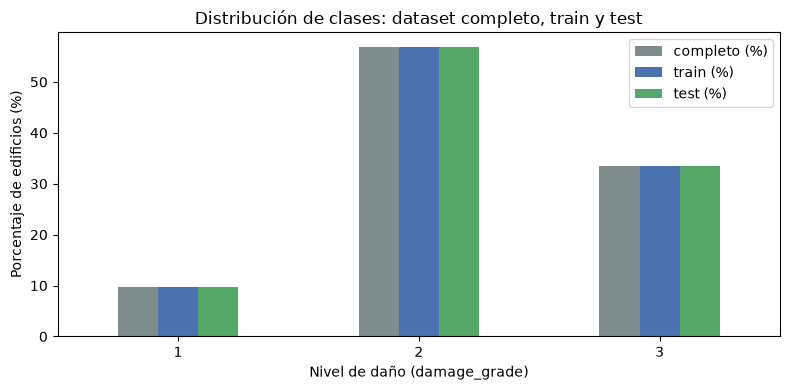

In [33]:
# Conteo y porcentaje de cada clase en el dataset completo, en train y en test
tabla = pd.DataFrame({
    "completo (%)": y.value_counts(normalize=True).sort_index() * 100,
    "train (n)": y_train.value_counts().sort_index(),
    "train (%)": y_train.value_counts(normalize=True).sort_index() * 100,
    "test (n)": y_test.value_counts().sort_index(),
    "test (%)": y_test.value_counts(normalize=True).sort_index() * 100,
}).round(2)
print(tabla)

# Gráfico comparativo de los porcentajes
ax = tabla[["completo (%)", "train (%)", "test (%)"]].plot(kind="bar", figsize=(8, 4),
                                                           color=["#7F8C8D", "#4C72B0", "#55A868"])
ax.set_title("Distribución de clases: dataset completo, train y test")
ax.set_xlabel("Nivel de daño (damage_grade)")
ax.set_ylabel("Porcentaje de edificios (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

---

# D. Modelado

Se entrenan 5 modelos de clasificación con el conjunto de entrenamiento y se evalúan sobre el de prueba. Para cada uno se muestran las métricas por clase (`classification_report`) y la matriz de confusión, y se guardan los resultados para la comparación de la Sección E.

### Contenido de la sección
- **D.1 Función de evaluación** reutilizable.
- **D.2 Regresión logística:** línea base lineal.
- **D.3 Árbol de decisión:** con exploración del hiperparámetro `max_depth`.
- **D.4 Random Forest:** conjunto de árboles.
- **D.5 HistGradientBoosting:** boosting de árboles, versión rápida.
- **D.6 KNN:** clasificación por vecinos más cercanos.

### D.1 Función de evaluación

Para no repetir código, una función entrena el modelo con train, predice sobre test, muestra las métricas y la matriz de confusión, y guarda los resultados.

**Métricas:**
- **Precision:** de los edificios que el modelo clasificó en una clase, qué fracción realmente era de esa clase.
- **Recall:** de los edificios que realmente eran de una clase, qué fracción detectó el modelo.
- **F1-score:** combina precision y recall en un solo número.
- **Support:** cuántos edificios de esa clase hay en test.
- **Accuracy:** fracción total de aciertos.
- **F1 macro:** promedio simple del F1 de las 3 clases, sin ponderar por tamaño; castiga al modelo que ignora la clase pequeña.
- **AUC (OvR):** área bajo la curva ROC comparando cada clase contra las otras dos (One-vs-Rest) y promediando.

**Funciones usadas en el código:**
- **`fit(X, y)`:** entrena el modelo.
- **`predict_proba(X)`:** probabilidad estimada de cada clase para cada fila.
- **`argmax`:** posición del valor más alto; sirve para elegir la clase con mayor probabilidad. Así se obtiene la predicción sin recalcular, lo que ahorra tiempo en modelos lentos como KNN.
- **`classes_`:** lista de clases que aprendió el modelo (1, 2, 3).
- **`classification_report`:** tabla de precision, recall, F1 y support por clase.
- **`confusion_matrix`:** cuenta, para cada clase real, cuántos edificios se predijeron en cada clase.
- **`sns.heatmap`:** dibuja una matriz como mapa de colores con los números encima.
- **`time.perf_counter()`:** reloj de alta precisión para medir cuánto tarda el entrenamiento.
- **`def`:** define una función reutilizable.

**Nota:** las cinco alternativas pueden tardar tiempos diferentes. Se mide el tiempo de entrenamiento y se usa `F1 macro` como criterio principal de comparación, porque las tres clases no tienen la misma frecuencia.

In [34]:
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report,
    confusion_matrix, roc_auc_score
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.base import clone
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import time

resultados = {}
modelos_entrenados = {}

def evaluar_modelo(nombre, modelo, X_train, y_train, X_test, y_test):
    """Entrena un modelo, calcula métricas y muestra su matriz de confusión."""
    inicio = time.perf_counter()
    modelo.fit(X_train, y_train)
    tiempo = time.perf_counter() - inicio

    pred = modelo.predict(X_test)
    probabilidades = modelo.predict_proba(X_test)

    accuracy = accuracy_score(y_test, pred)
    f1_macro = f1_score(y_test, pred, average="macro")
    try:
        auc_macro = roc_auc_score(
            y_test, probabilidades,
            multi_class="ovr", average="macro",
            labels=modelo.classes_
        )
    except (ValueError, TypeError):
        auc_macro = np.nan

    print(f"\n===== {nombre} =====")
    print(f"Tiempo de entrenamiento: {tiempo:.2f} segundos")
    print(f"Accuracy: {accuracy:.4f}")
    print(f"F1 macro: {f1_macro:.4f}")
    print(f"AUC macro OvR: {auc_macro:.4f}")
    print("\nInforme por clase:")
    print(classification_report(y_test, pred, zero_division=0))

    cm = confusion_matrix(y_test, pred, labels=modelo.classes_)
    plt.figure(figsize=(6, 4))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=modelo.classes_, yticklabels=modelo.classes_
    )
    plt.title(f"Matriz de confusión — {nombre}")
    plt.xlabel("Clase predicha")
    plt.ylabel("Clase real")
    plt.tight_layout()
    plt.show()

    resultados[nombre] = {
        "accuracy": accuracy,
        "f1_macro": f1_macro,
        "auc_macro_ovr": auc_macro,
        "tiempo_segundos": tiempo
    }
    modelos_entrenados[nombre] = modelo
    return modelo


### D.2 Regresión logística

Se utiliza como modelo de referencia. `max_iter=1000` permite más iteraciones para que el algoritmo alcance la convergencia; `class_weight="balanced"` asigna mayor peso a las clases menos frecuentes.


===== Regresión logística =====
Tiempo de entrenamiento: 9.51 segundos
Accuracy: 0.6958
F1 macro: 0.6695
AUC macro OvR: 0.8653

Informe por clase:
              precision    recall  f1-score   support

           1       0.45      0.84      0.58      5025
           2       0.80      0.65      0.72     29652
           3       0.69      0.73      0.71     17444

    accuracy                           0.70     52121
   macro avg       0.64      0.74      0.67     52121
weighted avg       0.73      0.70      0.70     52121



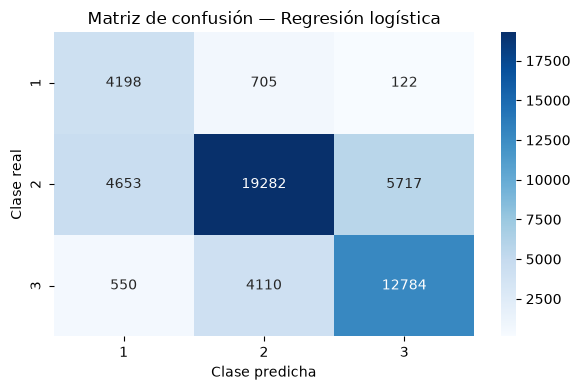

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to u

In [35]:
modelo_logistico = LogisticRegression(
    max_iter=1000, class_weight="balanced", random_state=42
)
evaluar_modelo(
    "Regresión logística", modelo_logistico,
    X_train, y_train, X_test, y_test
)


### D.3 Árbol de decisión

El árbol aprende reglas a partir de las características. Se limita inicialmente su profundidad para controlar la complejidad; más adelante se explorarán hiperparámetros.


===== Árbol de decisión =====
Tiempo de entrenamiento: 2.68 segundos
Accuracy: 0.6628
F1 macro: 0.6335
AUC macro OvR: 0.8022

Informe por clase:
              precision    recall  f1-score   support

           1       0.42      0.76      0.54      5025
           2       0.78      0.61      0.69     29652
           3       0.64      0.72      0.68     17444

    accuracy                           0.66     52121
   macro avg       0.61      0.70      0.63     52121
weighted avg       0.70      0.66      0.67     52121



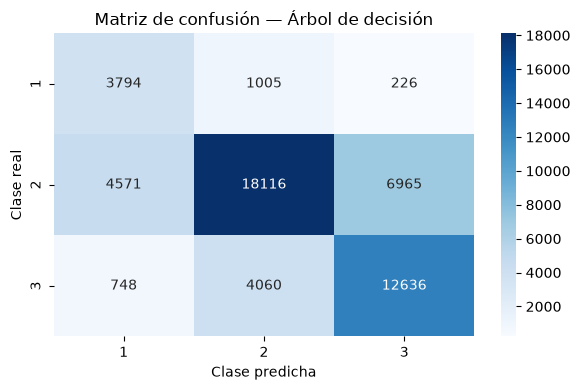

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",20
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: dict, list of dict or ""balanced"", default=NoneWeights associated with classes in the form ``{class_label: weight}``.If None, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_fea

In [36]:
modelo_arbol = DecisionTreeClassifier(
    max_depth=20, min_samples_leaf=5,
    class_weight="balanced", random_state=42
)
evaluar_modelo(
    "Árbol de decisión", modelo_arbol,
    X_train, y_train, X_test, y_test
)


### D.4 Random Forest

Random Forest combina varios árboles entrenados con variaciones de los datos y las características. `n_jobs=-1` permite utilizar los núcleos disponibles.


===== Random Forest =====
Tiempo de entrenamiento: 4.03 segundos
Accuracy: 0.7418
F1 macro: 0.7112
AUC macro OvR: 0.8800

Informe por clase:
              precision    recall  f1-score   support

           1       0.57      0.73      0.64      5025
           2       0.78      0.77      0.78     29652
           3       0.73      0.70      0.71     17444

    accuracy                           0.74     52121
   macro avg       0.70      0.73      0.71     52121
weighted avg       0.75      0.74      0.74     52121



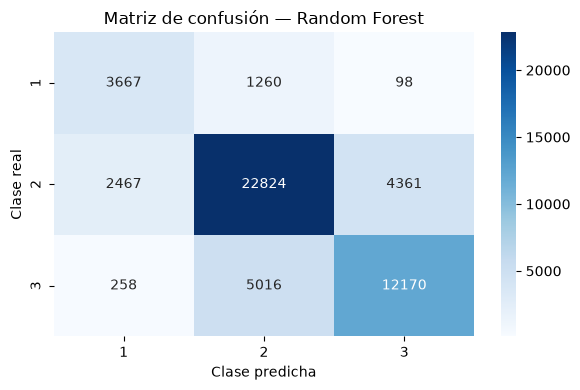

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",120
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",2
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced_subsample'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consid

In [37]:
modelo_rf = RandomForestClassifier(
    n_estimators=120, max_depth=None, min_samples_leaf=2,
    class_weight="balanced_subsample", n_jobs=-1,
    random_state=42
)
evaluar_modelo(
    "Random Forest", modelo_rf,
    X_train, y_train, X_test, y_test
)


### D.5 HistGradientBoosting

Este modelo construye árboles de manera secuencial, buscando corregir errores de los anteriores. Se incluye como alternativa de boosting.


===== HistGradientBoosting =====
Tiempo de entrenamiento: 5.28 segundos
Accuracy: 0.7482
F1 macro: 0.6979
AUC macro OvR: 0.8797

Informe por clase:
              precision    recall  f1-score   support

           1       0.68      0.54      0.60      5025
           2       0.75      0.85      0.80     29652
           3       0.77      0.64      0.70     17444

    accuracy                           0.75     52121
   macro avg       0.73      0.68      0.70     52121
weighted avg       0.75      0.75      0.74     52121



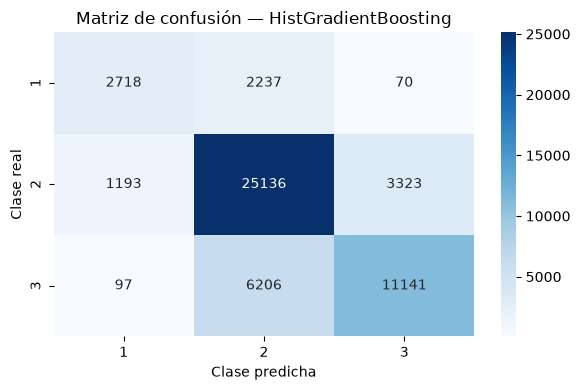

,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees for binary classification. For multiclassclassification, `n_classes` trees per iteration are built.",120
,"random_state random_state: int, RandomState instance or None, default=NonePseudo-random number generator to control the subsampling in thebinning process, and the train/validation data split if early stoppingis enabled.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'log_loss'}, default='log_loss'The loss function to use in the boosting process.For binary classification problems, 'log_loss' is also known as logistic loss,binomial deviance or binary crossentropy. Internally, the model fits one treeper boosting iteration and uses the logistic sigmoid function (expit) asinverse link function to compute the predicted positive class probability.For multiclass classification problems, 'log_loss' is also known as multinomialdeviance or categorical crossentropy. Internally, the model fits one tree perboosting iteration and per class and uses the softmax function as inverse linkfunction to compute the predicted probabilities of the classes.",'log_loss'
,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",0.1
,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",31
,"max_depth max_depth: int or None, default=NoneThe maximum depth of each tree. The depth of a tree is the number ofedges to go from the root to the deepest leaf.Depth isn't constrained by default.",None
,"min_samples_leaf min_samples_leaf: int, default=20The minimum number of samples per leaf. For small datasets with lessthan a few hundred samples, it is recommended to lower this valuesince only very shallow trees would be built.",20
,"l2_regularization l2_regularization: float, default=0The L2 regularization parameter penalizing leaves with small hessians.Use ``0`` for no regularization (default).",0.0
,"max_features max_features: float, default=1.0Proportion of randomly chosen features in each and every node split.This is a form of regularization, smaller values make the trees weakerlearners and might prevent overfitting.If interaction constraints from `interaction_cst` are present, only allowedfeatures are taken into account for the subsampling... versionadded:: 1.4",1.0
,"max_bins max_bins: int, default=255The maximum number of bins to use for non-missing values. Beforetraining, each feature of the input array `X` is binned intointeger-valued bins, which allows for a much faster training stage.Features with a small number of unique values may use less than``max_bins`` bins. In addition to the ``max_bins`` bins, one more binis always reserved for missing values. Must be no larger than 255.",255
,"categorical_features categorical_features: array-like of {bool, int, str} of shape (n_features) or shape (n_categorical_features,), default='from_dtype'Indicates the categorical features.- None : no feature will be considered categorical.- boolean array-like : boolean mask indicating categorical features.- integer array-like : integer indices indicating categorical features.- str array-like: names of categorical features (assuming the training data has feature names).- `""from_dtype""`: dataframe columns with dtype ""Categorical"" and ""Enum"" are considered to be categorical features. The input must be a dataframe that is supported by narwhals (or supports it): :func:`narwhals.from_native` must work. This is the case, for instance, for pandas and polars DataFrames.For each categorical feature, there must be at most `max_bins` uniquecategories. Negative values for categorical features encoded as numericdtypes are treated as missing val

In [38]:
modelo_hgb = HistGradientBoostingClassifier(
    max_iter=120, learning_rate=0.1,
    max_leaf_nodes=31, random_state=42
)
evaluar_modelo(
    "HistGradientBoosting", modelo_hgb,
    X_train, y_train, X_test, y_test
)


### D.6 K vecinos más cercanos (KNN)

KNN clasifica cada edificio según los vecinos más cercanos en el espacio de características. Como depende de distancias, el escalado de las variables numéricas es especialmente importante. En este dataset grande, la predicción puede tardar más que en otros modelos.


===== KNN =====
Tiempo de entrenamiento: 0.10 segundos
Accuracy: 0.7145
F1 macro: 0.6585
AUC macro OvR: 0.8377

Informe por clase:
              precision    recall  f1-score   support

           1       0.61      0.49      0.55      5025
           2       0.73      0.81      0.77     29652
           3       0.71      0.62      0.66     17444

    accuracy                           0.71     52121
   macro avg       0.68      0.64      0.66     52121
weighted avg       0.71      0.71      0.71     52121



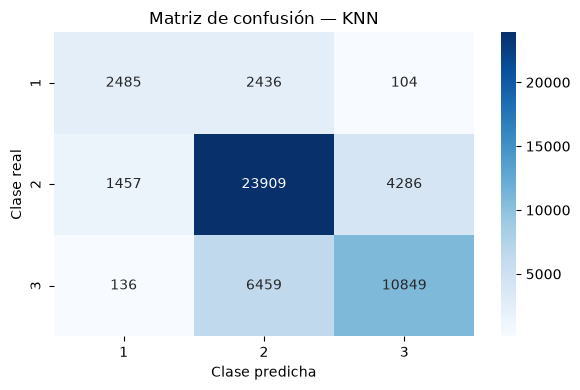

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",11
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'distance'
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",-1
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](3,)","[1,2,3]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [39]:
modelo_knn = KNeighborsClassifier(
    n_neighbors=11, weights="distance", n_jobs=-1
)
evaluar_modelo(
    "KNN", modelo_knn,
    X_train, y_train, X_test, y_test
)


---

# E. Evaluación comparativa

Se reúnen las métricas de los cinco modelos en una tabla y se comparan visualmente. El mejor modelo se seleccionará principalmente por su F1 macro, revisando también accuracy, AUC y el comportamiento de cada clase.

,accuracy,f1_macro,auc_macro_ovr,tiempo_segundos
Random Forest,0.7418,0.7112,0.8800,4.0347
HistGradientBoosting,0.7482,0.6979,0.8797,5.2755
Regresión logística,0.6958,0.6695,0.8653,9.5140
KNN,0.7145,0.6585,0.8377,0.0977
Árbol de decisión,0.6628,0.6335,0.8022,2.6760


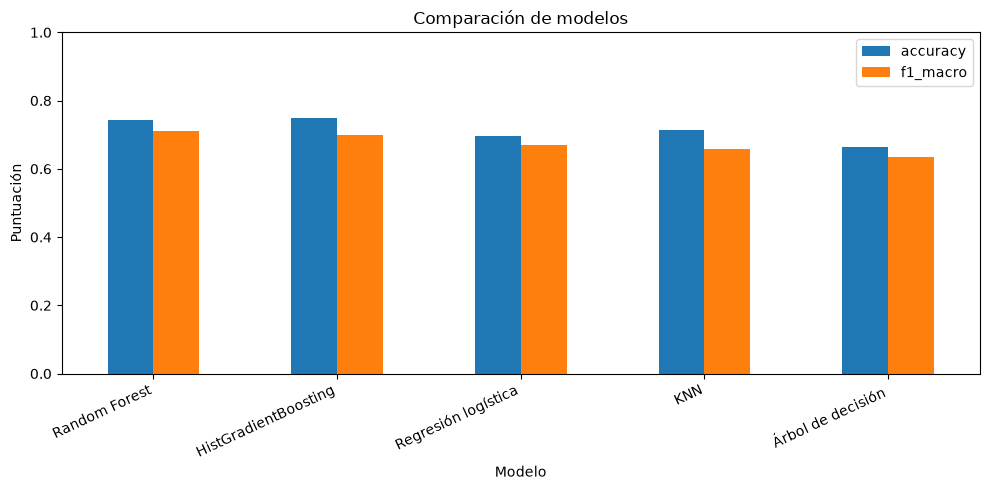

Mejor modelo según F1 macro: Random Forest


In [40]:
tabla_resultados = pd.DataFrame(resultados).T
tabla_resultados = tabla_resultados.sort_values("f1_macro", ascending=False)
display(tabla_resultados.round(4))

ax = tabla_resultados[["accuracy", "f1_macro"]].plot(
    kind="bar", figsize=(10, 5), ylim=(0, 1)
)
ax.set_title("Comparación de modelos")
ax.set_xlabel("Modelo")
ax.set_ylabel("Puntuación")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

mejor_nombre = tabla_resultados["f1_macro"].idxmax()
mejor_modelo_inicial = modelos_entrenados[mejor_nombre]
print("Mejor modelo según F1 macro:", mejor_nombre)


### E.1 Curvas ROC de dos modelos

Como el problema tiene tres clases, aquí se compara la capacidad de identificar la clase 3 (daño casi total) frente a las clases 1 y 2. Se superponen las curvas ROC de la regresión logística y del modelo con mayor F1 macro. Si el mejor modelo también es la regresión logística, se usa el segundo mejor para que la comparación incluya dos modelos distintos.

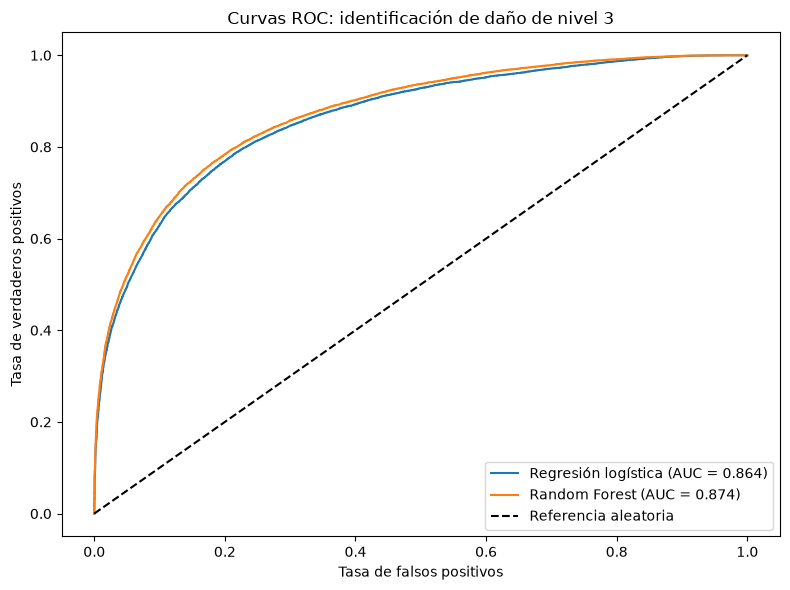

In [41]:
from sklearn.metrics import roc_curve, auc

nombres_roc = ["Regresión logística", mejor_nombre]
if nombres_roc[1] == nombres_roc[0]:
    nombres_roc[1] = tabla_resultados.index[1]

y_binario = (y_test == 3).astype(int)
plt.figure(figsize=(8, 6))

for nombre in nombres_roc:
    modelo = modelos_entrenados[nombre]
    indice_clase_3 = list(modelo.classes_).index(3)
    proba_clase_3 = modelo.predict_proba(X_test)[:, indice_clase_3]
    fpr, tpr, _ = roc_curve(y_binario, proba_clase_3)
    area_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{nombre} (AUC = {area_auc:.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Referencia aleatoria")
plt.title("Curvas ROC: identificación de daño de nivel 3")
plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos")
plt.legend()
plt.tight_layout()
plt.show()


### E.2 Análisis comparativo

Después de ejecutar las celdas anteriores, completa el siguiente análisis con los valores reales de la tabla. No afirmes que un modelo es mejor sin apoyarte en las métricas.

- El modelo con mayor F1 macro fue **[escribir nombre]**, con **[escribir valor]**.
- Su accuracy fue **[escribir valor]** y su AUC macro OvR fue **[escribir valor]**.
- El F1 macro es importante porque promedia el rendimiento de las tres clases sin dar más peso a la clase mayoritaria.
- La matriz de confusión y el informe por clase permiten comprobar qué niveles de daño identifica peor.
- La curva ROC muestra la capacidad de distinguir edificios con daño de nivel 3 frente a los demás niveles.
- La elección final debe considerar el rendimiento, el tiempo de entrenamiento y el costo de predicción, no solo una métrica.

---

# F. Modelo final y serialización

Se realiza una búsqueda de hiperparámetros sobre el modelo que obtuvo el mayor F1 macro. Para reducir el tiempo de búsqueda, se utiliza una muestra estratificada del conjunto de entrenamiento; luego, el modelo con los mejores hiperparámetros se vuelve a entrenar con todo `X_train`. El conjunto `X_test` se mantiene reservado para la evaluación final.

Fitting 3 folds for each of 6 candidates, totalling 18 fits
Modelo seleccionado: Random Forest
Mejores hiperparámetros: {'n_estimators': 80, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 20, 'class_weight': 'balanced_subsample'}
Mejor F1 macro en validación cruzada: 0.6868

Evaluación final en test
Accuracy: 0.7301
F1 macro: 0.7007
AUC macro OvR: 0.877
              precision    recall  f1-score   support

           1       0.54      0.75      0.63      5025
           2       0.79      0.74      0.76     29652
           3       0.71      0.72      0.71     17444

    accuracy                           0.73     52121
   macro avg       0.68      0.73      0.70     52121
weighted avg       0.74      0.73      0.73     52121



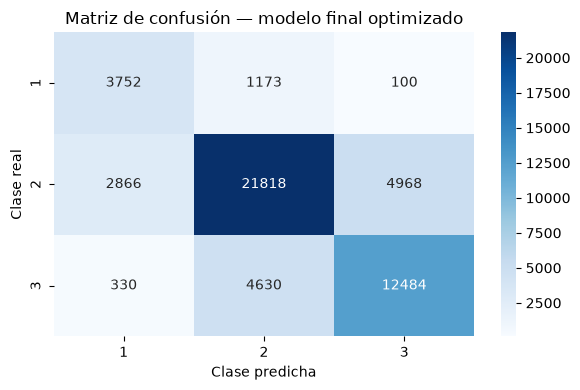

In [42]:
from sklearn.model_selection import RandomizedSearchCV, train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score, roc_auc_score
from sklearn.base import clone
from scipy.stats import randint, loguniform
import joblib
import os

# Muestra estratificada para acelerar la búsqueda de hiperparámetros
X_busqueda, _, y_busqueda, _ = train_test_split(
    X_train, y_train, train_size=0.30,
    stratify=y_train, random_state=42
)

# Espacio de búsqueda específico para cada modelo posible
espacios = {
    "Regresión logística": {
        "C": [0.1, 1.0, 3.0],
        "class_weight": [None, "balanced"]
    },
    "Árbol de decisión": {
        "max_depth": [10, 20, 30, None],
        "min_samples_split": [2, 10, 20],
        "min_samples_leaf": [1, 5, 10],
        "class_weight": [None, "balanced"]
    },
    "Random Forest": {
        "n_estimators": [80, 120],
        "max_depth": [20, 30, None],
        "min_samples_leaf": [1, 3],
        "max_features": ["sqrt", 0.8],
        "class_weight": [None, "balanced_subsample"]
    },
    "HistGradientBoosting": {
        "max_iter": [80, 120, 160],
        "learning_rate": [0.05, 0.1],
        "max_leaf_nodes": [15, 31],
        "l2_regularization": [0.0, 1.0]
    },
    "KNN": {
        "n_neighbors": [5, 11, 21],
        "weights": ["uniform", "distance"],
        "p": [1, 2]
    }
}

# Se crea una copia del mejor modelo inicial y se exploran sus hiperparámetros
modelo_para_busqueda = clone(modelos_entrenados[mejor_nombre])

busqueda = RandomizedSearchCV(
    estimator=modelo_para_busqueda,
    param_distributions=espacios[mejor_nombre],
    n_iter=6,
    scoring="f1_macro",
    cv=3,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    refit=True
)

busqueda.fit(X_busqueda, y_busqueda)
print("Modelo seleccionado:", mejor_nombre)
print("Mejores hiperparámetros:", busqueda.best_params_)
print("Mejor F1 macro en validación cruzada:", round(busqueda.best_score_, 4))

# Reentrenamiento con todos los datos de entrenamiento
modelo_final = clone(busqueda.best_estimator_)
modelo_final.fit(X_train, y_train)

pred_final = modelo_final.predict(X_test)
proba_final = modelo_final.predict_proba(X_test)

print("\nEvaluación final en test")
print("Accuracy:", round(accuracy_score(y_test, pred_final), 4))
print("F1 macro:", round(f1_score(y_test, pred_final, average="macro"), 4))
print("AUC macro OvR:", round(
    roc_auc_score(y_test, proba_final, multi_class="ovr",
                  average="macro", labels=modelo_final.classes_), 4
))
print(classification_report(y_test, pred_final, zero_division=0))

cm_final = confusion_matrix(y_test, pred_final, labels=modelo_final.classes_)
plt.figure(figsize=(6, 4))
sns.heatmap(cm_final, annot=True, fmt="d", cmap="Blues",
            xticklabels=modelo_final.classes_,
            yticklabels=modelo_final.classes_)
plt.title("Matriz de confusión — modelo final optimizado")
plt.xlabel("Clase predicha")
plt.ylabel("Clase real")
plt.tight_layout()
plt.show()


### F.1 Guardar, cargar y probar el modelo

`joblib.dump()` guarda el modelo entrenado en un archivo. `joblib.load()` lo carga de nuevo. La predicción de ejemplo utiliza filas de test que el modelo no utilizó para entrenarse, pero que ya están transformadas con el mismo preprocesamiento aplicado a los datos de entrenamiento.

In [43]:
ruta_modelo = "modelo_terremoto.joblib"
joblib.dump(modelo_final, ruta_modelo)
print("Modelo guardado en:", os.path.abspath(ruta_modelo))

modelo_cargado = joblib.load(ruta_modelo)
X_nuevo = X_test.iloc[:5]
predicciones_nuevas = modelo_cargado.predict(X_nuevo)

ejemplo = pd.DataFrame({
    "damage_grade_real": y_test.iloc[:5].values,
    "damage_grade_predicho": predicciones_nuevas
}, index=X_nuevo.index)
display(ejemplo)


Modelo guardado en: d:\ingeniería de sistemas\semestre 5\ingenieria del conocimiento\proyecto\parcial\Ejer1\modelo_terremoto.joblib


,damage_grade_real,damage_grade_predicho
124536,3,2
112152,2,2
93613,2,1
204895,2,2
37356,3,3


### F.2 Importancia por permutación

Se estima qué características afectan más al rendimiento del modelo final. Para reducir el tiempo de cálculo, se utiliza una muestra de test y pocas repeticiones. Una importancia alta significa que al desordenar esa característica empeora más el resultado; no implica por sí sola causalidad.

,caracteristica,importancia_media,desviacion
100,te_geo_level_3_id_1,0.0409,0.0018
102,te_geo_level_3_id_3,0.0227,0.0005
101,te_geo_level_3_id_2,0.0160,0.0044
1,age,0.0092,0.0022
99,te_geo_level_2_id_3,0.0078,0.0032
97,te_geo_level_2_id_1,0.0077,0.0037
5,has_superstructure_mud_mortar_stone,0.0060,0.0021
2,area_percentage,0.0054,0.0036
51,position_t,0.0036,0.0011
0,count_floors_pre_eq,0.0030,0.0016


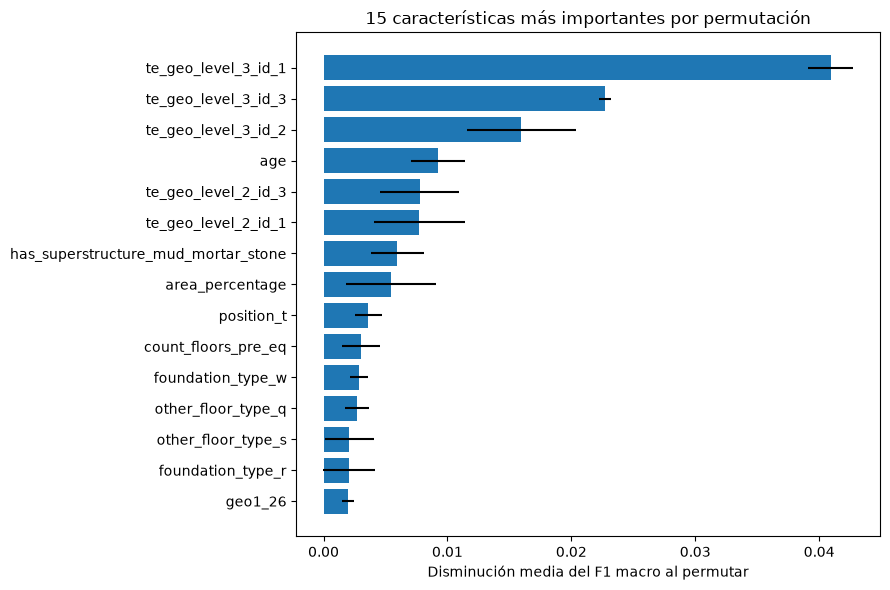

In [44]:
from sklearn.inspection import permutation_importance

# Submuestra para que el cálculo sea razonable en un dataset grande
n_muestra = min(3000, len(X_test))
X_imp = X_test.sample(n=n_muestra, random_state=42)
y_imp = y_test.loc[X_imp.index]

importancias = permutation_importance(
    modelo_final, X_imp, y_imp,
    scoring="f1_macro", n_repeats=2,
    random_state=42, n_jobs=-1
)

tabla_importancia = pd.DataFrame({
    "caracteristica": X_imp.columns,
    "importancia_media": importancias.importances_mean,
    "desviacion": importancias.importances_std
}).sort_values("importancia_media", ascending=False)

display(tabla_importancia.head(15).round(4))

top = tabla_importancia.head(15).sort_values("importancia_media")
plt.figure(figsize=(9, 6))
plt.barh(top["caracteristica"], top["importancia_media"], xerr=top["desviacion"])
plt.title("15 características más importantes por permutación")
plt.xlabel("Disminución media del F1 macro al permutar")
plt.tight_layout()
plt.show()


---

# G. Conclusiones

**Completa esta sección después de ejecutar el notebook**, reemplazando los espacios con los resultados obtenidos. No inventes métricas ni afirmes mejoras que no se observen en las salidas.

1. **Dataset y EDA:** se analizaron 260,601 edificios del terremoto de Nepal de 2015. La variable objetivo `damage_grade` tiene tres clases y está desbalanceada; por ello, además de accuracy, se revisó F1 macro y el rendimiento por clase.
2. **Preprocesamiento:** el valor 995 de `age` se trató como dato desconocido, se creó un indicador y se imputó con la mediana calculada solo en train. Las variables categóricas se codificaron y las variables numéricas se escalaron sin utilizar información del test para ajustar esas transformaciones.
3. **Comparación de modelos:** el mejor modelo inicial según F1 macro fue **[nombre]**, con **[valor]**. Esto se debe interpretar junto con su matriz de confusión y las métricas de cada clase.
4. **Optimización:** con `RandomizedSearchCV` se exploraron hiperparámetros del modelo seleccionado. El F1 macro en test del modelo final fue **[valor]**, frente a **[valor]** del modelo inicial seleccionado.
5. **Características relevantes:** según la importancia por permutación, las características con mayor impacto fueron **[mencionar las primeras]**. Esta medida describe importancia predictiva, no causalidad.
6. **Limitaciones:** las etiquetas representan niveles de daño del conjunto de datos y no garantizan que el modelo se comporte igual en otros terremotos, países o tipos de construcción.
7. **Mejoras futuras:** probar validación cruzada más extensa, evaluar otras estrategias para la clase minoritaria y comprobar el modelo con datos de otra región antes de usarlo en una situación real.

## Antes de entregar: lista de verificación

- [ ] Confirmar que `train_merged.csv` esté incluido en Colab o que la celda de carga use una ruta accesible.
- [ ] Completar los nombres y códigos de todos los integrantes reales del grupo.
- [ ] Ejecutar el notebook desde el principio, en orden, con **Entorno de ejecución → Ejecutar todas**.
- [ ] Revisar que todas las celdas terminen sin errores y que los gráficos se muestren.
- [ ] Sustituir los espacios de las conclusiones por los resultados reales.
- [ ] Guardar el notebook `.ipynb` con las salidas finales.
- [ ] Cada integrante debe poder explicar el preprocesamiento, las métricas, el modelo elegido y la optimización.

**Importante:** el archivo de modelo generado (`modelo_terremoto.joblib`) recibe características ya preprocesadas. Para usar datos crudos nuevos en una aplicación real, también habría que guardar y aplicar el mismo preprocesamiento (imputador, codificadores, escalador y orden de columnas).